# `Decision tree`


In [1]:
print("Decision Tree section starting here . ")

Decision Tree section starting here . 


In [2]:
# What is Decision tree ? 

# A Decision Tree is a supervised machine learning algorithm that makes predictions by repeatedly splitting data using simple decision rules, creating a tree-like structure.

# it can use both types regression and classiifcation . 

# Decision Tree all info writen below the link . 


https://docs.google.com/document/d/1XMz6b2HjoS1fvBCZ_j5DZsiMCSwLoOk3FUYmI67Hatw/edit?usp=sharing

# All important note and interview question and answer 



https://docs.google.com/document/d/1BdvKqwxW7LIz57N3S3LY_LgG-NmYcjEN77242Ti6a3g/edit?usp=sharing

# Decision Tree Project 

`Given measurements of a breast tumor, predict whether it is malignant or benign.`

`This is`
`A Supervised learning :-  because we have labels.`

`Classification - because the output is a class`

`Binary Classification -> because these are 2 class`

In [11]:
import numpy as np # numpy is used for numerical operations and array handling.
import pandas as pd # pandas is used for working with tabular data.
import matplotlib.pyplot as plt # matplotlib is used for visualization.
from sklearn.datasets import load_breast_cancer # loads the build in breast cancer from scikit learn.
from sklearn.model_selection import train_test_split # splits our dataset into training and testing data.
from sklearn.tree import DecisionTreeClassifier# imports the Decision Tree classification algorithm.
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
# accuracy_score - calculates prediction accuracy.
# confusion_matrix - shows correct and incorrect classifications.
# classification_report - gives precision, recall and F1-score.

/Users/shyamalkar/Desktop/ML/mlvenv/lib/python3.14/site-packages/scipy/sparse/_sputils.py:17: FutureWarning: In the future `np.long` will be defined as the corresponding NumPy scalar.
  np.uintc, np.long, np.ulong, np.longlong, np.ulonglong,


AttributeError: module 'numpy' has no attribute 'long'

`Load the dataset`

In [12]:
data = load_breast_cancer() # loads the breast cancer dataset into the variable 'data' .
#This dataset is already prepared, so we don't need unnecessary cleaning . 


NameError: name 'load_breast_cancer' is not defined

In [ ]:
print(data)
#Display information stored inside the scikit learn dataset object . 

{'data': array([[1.799e+01, 1.038e+01, 1.228e+02, ..., 2.654e-01, 4.601e-01,
        1.189e-01],
       [2.057e+01, 1.777e+01, 1.329e+02, ..., 1.860e-01, 2.750e-01,
        8.902e-02],
       [1.969e+01, 2.125e+01, 1.300e+02, ..., 2.430e-01, 3.613e-01,
        8.758e-02],
       ...,
       [1.660e+01, 2.808e+01, 1.083e+02, ..., 1.418e-01, 2.218e-01,
        7.820e-02],
       [2.060e+01, 2.933e+01, 1.401e+02, ..., 2.650e-01, 4.087e-01,
        1.240e-01],
       [7.760e+00, 2.454e+01, 4.792e+01, ..., 0.000e+00, 2.871e-01,
        7.039e-02]], shape=(569, 30)), 'target': array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0,
       0, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0, 1, 0, 0,
       1, 1, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0,
       1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0, 1,
       1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 0, 0, 1, 1, 1, 0,

In [ ]:
data.data.shape 
# 569 - number of samples / observations. 
# 30 - number of input features. 

(569, 30)

`Check the feature names`

In [ ]:
print(data.feature_names)
# displays the names of the 30 features.
# these features describe different characteristics of the tumors.

['mean radius' 'mean texture' 'mean perimeter' 'mean area'
 'mean smoothness' 'mean compactness' 'mean concavity'
 'mean concave points' 'mean symmetry' 'mean fractal dimension'
 'radius error' 'texture error' 'perimeter error' 'area error'
 'smoothness error' 'compactness error' 'concavity error'
 'concave points error' 'symmetry error' 'fractal dimension error'
 'worst radius' 'worst texture' 'worst perimeter' 'worst area'
 'worst smoothness' 'worst compactness' 'worst concavity'
 'worst concave points' 'worst symmetry' 'worst fractal dimension']


In [ ]:
# display the numeric target labels. and target contains 0 & 1
data.target

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0,
       0, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0, 1, 0, 0,
       1, 1, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0,
       1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0, 1,
       1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 0, 1, 0,
       0, 1, 0, 0, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 0, 1, 1, 1, 1, 0, 0, 1, 0, 1, 1, 0, 0, 1, 1, 0, 0, 1, 1, 1,
       1, 0, 1, 1, 0, 0, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1, 0, 0, 1, 0, 0,
       0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0,
       1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1, 0, 1, 1, 0, 0, 1, 0, 1, 1,
       1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 0, 1, 1, 0, 1, 0, 0, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0,

`Check the class name`

In [ ]:
data.target_names # 0 hold malignant and 1 hold benign

array(['malignant', 'benign'], dtype='<U9')

`Check class distribution`

In [ ]:
# this is an important step for classification problem.

unique = np.unique(data.target, return_counts=True)
# you can ofcourse use count , so count help up how many target label has in this dataset . 
# unique : finds the different class (0, 1)
# counts : counts how many samples belong to each class .  

print(unique)

# you probably see here the output would be - 0,1 & where 0 means malignant and 1 means benign 212 malignant and 357 is benign. 

(array([0, 1]), array([212, 357]))


# Create X and y 

In [ ]:
X = data.data
# X represents the input features . 
# Shape: (569, 30)
# 569 samples and 30 features. 

y = data.target
# y represents the target/label
# shape:  (569,)
# 0 is the malignent and 1 is benign

print(X.shape, "569 samples and 30 features. is the target and 0 malignent and 1 benign")
print(y.shape, "is the target and 0 malignent and 1 benign")


(569, 30) 569 samples and 30 features. is the target and 0 malignent and 1 benign
(569,) is the target and 0 malignent and 1 benign


`So - X is what the model sees and y is what the model needs to predict`

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)
# X_train → 80% of the input data used for training.
# X_test  → 20% of the input data used for testing. 
#
# y_train → correct labels for X_train.
# y_test  → correct labels for X_test.
#
# test_size=0.2 → 20% goes to testing and 80% to training.
#
# stratify=y → keeps approximately the same proportion of
#              malignant and benign samples in both datasets.
#
# random_state=42 → makes the random split reproducible.
#                   42 does NOT mean 42 splits.

`Check the shapes`

In [ ]:
print("The real shape of this data", X.shape)
# Complete dataset  (569, 30)

print("Data shape after X_train:", X_train.shape)
# Training data  approximately (455, 30)

print("Data shape after X_test:", X_test.shape)
# Testing data  approximately (114, 30)

print("Data shape after y_train:", y_train.shape)
# Training labels  approximately (455,)

print("Data shape after y_test:", y_test.shape)
# Testing labels  approximately (114,)

The real shape of this data (569, 30)
Data shape after X_train: (455, 30)
Data shape after X_test: (114, 30)
Data shape after y_train: (455,)
Data shape after y_test: (114,)


`Create the Decision Tree`

`Now we actually crate our algorithm`

In [ ]:
classifier = DecisionTreeClassifier( # creates a decision tree classifier model . 
    
    criterion='gini', # criterian='gini' tells the tree to use Gini Impurity , to decide which splits are usefull.

    max_depth=3, # In a decision tree, max_depth=3 means the longest path from the root node to a leaf node can have at most 3 sequential steps (or splits).

    random_state=42) # random state makes the result reproducible . 

# At this point the tree has not learned anything yet . 
# we have only created the model . 

# but the question is Why gini ? 
# Which feature and threshold should i use to split the data . 
# gini impurity  helps the tree choose a split that creates more pure groups. 


`Train the decision tree `

In [ ]:
classifier.fit(X_train, y_train)

# train the decision tree using training data. 
#
# X_train - tumor measurements
# y_train - correct malignent/benign labels. 
# 
# the tree learns decision rules from the training data . 

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at 

`Make prediction on training data`

In [ ]:
X_train_prediction = classifier.predict(X_train)
# uses the trained decision tree to predict the classes. 
# of the training samples. 
# 
# The output contains predict such as - 0,1,1,0......

`Training accuracy`

In [ ]:
training_data_accuracy = accuracy_score(y_train, X_train_prediction)

# compares the actual training labels(y_train)
# with the model's predictions. 
# if calculates the percentage of correct predictions . 
print("Training accuracy:", training_data_accuracy)
# output 1.0 means 100% accuracy 
# A decision tree can be easyly overfit .

Training accuracy: 0.9758241758241758


`Make prediction on test data`

In [ ]:
X_test_prediction = classifier.predict(X_test)
# Gives the unseen test samples to the trained Decision Tree.
#
# The model has NOT trained on X_test.
# It must use the rules learned from X_train.

In [ ]:
testing_data_accuracy = accuracy_score(y_test, X_test_prediction)
training_data_accuracy


0.9758241758241758

`Test accuracy`

In [ ]:
test_data_accuracy = accuracy_score(
    y_test,
    X_test_prediction
)
# Compares the actual test labels with the model's predictions.
# Calculates the percentage of correct test predictions.

In [ ]:
print("Test accuracy:", test_data_accuracy)
# display the model performs in unseen data

Test accuracy: 0.9385964912280702


`Accuray alone isn't enough `

`Confusion Matrix`

In [ ]:
cm = confusion_matrix(y_test, X_test_prediction)
# Creates a confusion matrix showing:
# True Negatives
# False Positives
# False Negatives
# True Positives

print(cm)
# Displays the confusion matrix.
# the output means -

[[38  4]
 [ 3 69]]


`Classification Report`

In [ ]:
print(
    classification_report(
        y_test,
        X_test_prediction,
        target_names=data.target_names
    )
)
# Generates:
# Precision
# Recall
# F1-score
# Support
#
# for both malignant and benign classes.

# This is important because in medical classification, accuracy alone may not be enough.

# For example, missing a malignant tumor can be much more serious than incorrectly classifying a benign tumor.

# A classification report is a performance evaluation tool in machine learning that display the precision,recall, F1-score, and support for each class classification model . 

# OutPut :-
#This table is a classification report. It measures how well your machine learning model diagnoses tumors as either malignant (cancerous) or benign (non-cancerous)

#Precision:- (Reliability when positive)
# Malignant (0.85): When the model predicts a tumor is malignant, it is correct 85% of the time.
# Benign (0.96): When the model predicts a tumor is benign, it is correct 96% of the time.


# Recall (Detection rate)
# Malignant (0.93): The model successfully finds 93% of all actual malignant tumors. It missed 7% (false negatives). 
# Benign (0.90): The model successfully finds 90% of all actual benign tumors.

# Support (The test sample count)
# This is the actual number of tumor samples in your test dataset. You tested 42 malignant cases and 72 benign cases, totaling 114.

# The AveragesAccuracy (0.91):
#  Overall, the model predicted the correct label for 91% of all 114 tumors.

# Macro Avg (0.91): The straight average of your metrics across both classes, treating both classes as equally important.
# Weighted Avg (0.91): The average adjusted for the fact that you have more benign samples (72) than malignant ones (42).


              precision    recall  f1-score   support

   malignant       0.93      0.90      0.92        42
      benign       0.95      0.96      0.95        72

    accuracy                           0.94       114
   macro avg       0.94      0.93      0.93       114
weighted avg       0.94      0.94      0.94       114



`Checking for overfitting `

In [ ]:
print("Training Accuracy:", training_data_accuracy)
# Accuracy on data the model learned from.

print("Test Accuracy:", test_data_accuracy)
# Accuracy on unseen data.


Training Accuracy: 0.9758241758241758
Test Accuracy: 0.9385964912280702


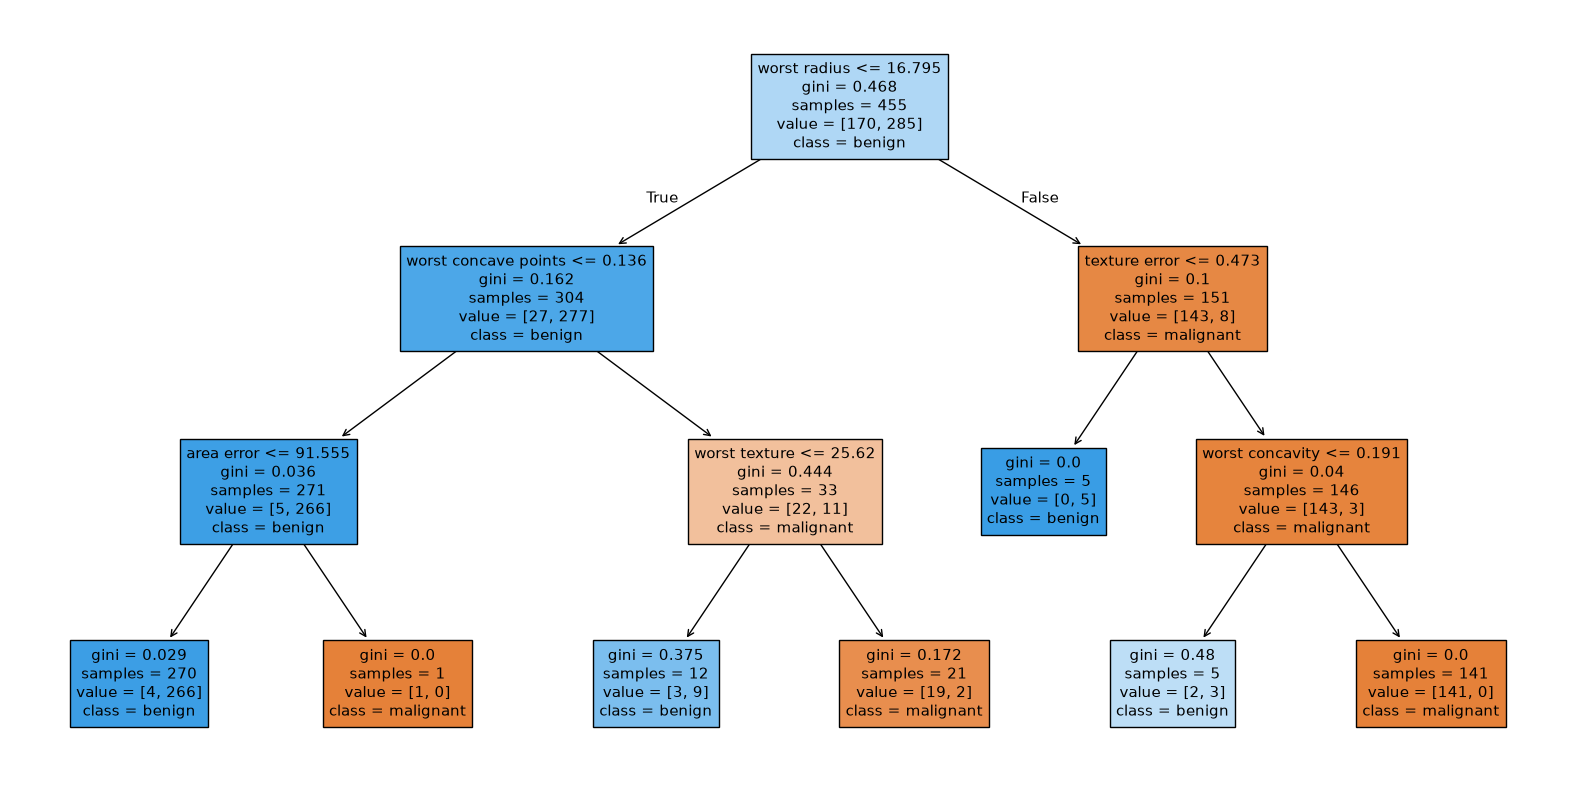

In [ ]:
from sklearn.tree import plot_tree
# Imports the function used to visualize the Decision Tree.

plt.figure(figsize=(20, 10))
# Creates a large figure so the tree is easier to see.

plot_tree(
    classifier,
    feature_names=data.feature_names,
    class_names=data.target_names,
    filled=True
)
# Draws the Decision Tree.
#
# feature_names → displays actual feature names.
# class_names → displays malignant/benign.
# filled=True → visually distinguishes the classes.

plt.show()
# Displays the tree.

# Training accuracy 1.0 and testing accuracy 0.91 that mean 91% accuracy . 
`it's may be overfit `
`So let's do customize for gain the better prediction , i add max_depth=3 , what does mean max_depth = 3 it means, he longest path from the root node to a leaf node can have at most 3 sequential steps (or splits). `

# Save model

In [ ]:
import pickle
# Imports pickle so we can save the trained model.

In [ ]:
with open('decision_tree_model.pkl', 'wb') as file:
    pickle.dump(classifier, file)
# Saves the trained Decision Tree to a .pkl file.
#
# 'wb' → write binary mode.
# pickle.dump() → writes the trained model into the file.